In [1]:
%load_ext autoreload
%autoreload 2
import jax.numpy as jnp
import jax_sn

import jax_sbgeom as jsb
from jax_sbgeom.jax_utils import mesh_to_pyvista_mesh
import pyvista as pv
from typing import Iterable
from jax_sn.domain.cross_sections import CrossSectionData, CrossSectionsIndexed
import numpy as onp 
import matplotlib.pyplot as plt

In [2]:
vmec_file = ["/home/tbogaarts/stellarator_paper/base_data/vmecs/helias5_vmec.nc4"][0]
fs_base = jsb.flux_surfaces.FluxSurfaceNormalExtendedNoPhi.from_hdf5(vmec_file)

In [3]:
flux_surface_extended = jsb.flux_surfaces.create_extended_flux_surface_d_interp_equal_arclength(fs_base, 1.5, 70, 80, 100)

In [4]:
dim = 2
degree = 4
tn_order = 3
n_elem_regions = (10, 1, 1, 10, 5, 1, 10, 2)
groups_list = (14.1e6, 10e6, 3e6, 1e6, 1e4, 300, 10,0)

d_regions_base = (1.2, 0.002, 0.025, 0.5, 0.385, 0.06, 0.2, 0.06)
l_order = 4
source_kwargs = {
    "n0"    : 2.4e20,
    "Ti0"   : 15.2,
    "nalpha": 0.35,
    "Tialpha": 1.2,
}
element = jax_sn.solution_domain.BasixLagrangianSimplex(degree, dim)

In [5]:
sum(d_regions_base)

2.432

In [6]:
from breeding_blanket_setup import _get_hcpb_data_openmc
new_bb_data_dict, new_aux_data_dict, tally_result_dict = _get_hcpb_data_openmc(d_regions_base, l_order, 1e4, groups_list)

/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=1.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=410.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda3/envs/jaxsbgeom/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=13.
  warn(msg, IDWarning)


In [7]:
def _get_mesh_and_source(d_regions_base : Iterable[int], n_elem_regions : Iterable[float], flux_surface_extended, n_theta : int, phi : float, source_kwargs : dict):
    s_power_sampling = 2
    regions_dim = [(sz, res) for sz, res in zip(d_regions_base, n_elem_regions)]
    cumsum_nodes  = jnp.concatenate([jnp.array([0]), jnp.cumsum(jnp.array([sz for sz, res in regions_dim]))])        
    s_array = jnp.concatenate([jnp.linspace(cumsum_nodes[0], cumsum_nodes[1], n_elem_regions[0], endpoint=False)**s_power_sampling]+ [jnp.linspace(cumsum_nodes[i], cumsum_nodes[i+1], n_elem_regions[i], endpoint=False) for i in range(1, len(regions_dim))] + [jnp.array([cumsum_nodes[-1]])])
    mesh_pol = jsb.flux_surfaces.flux_surface_meshing.mesh_poloidal_plane(flux_surface_extended,s_array, phi, n_theta )
    coordinates_pol = jsb.flux_surfaces.flux_surface_meshing._mesh_poloidal_points_coordinates(flux_surface_extended, s_array, phi, n_theta, True)
    region_plasma_indices = jnp.concatenate([jnp.zeros(n_theta), jnp.zeros(2 * n_theta * (n_elem_regions[0]-1))])
    
    for i in range(1, len(n_elem_regions)):
        region_plasma_indices = jnp.concatenate([region_plasma_indices, jnp.ones(2 * n_theta * n_elem_regions[i]) * i])        

    fs_values = jnp.nan_to_num(jsb.interfaces.plasma.flux_surface_reaction_rates_simple(coordinates_pol[0], **source_kwargs), nan = 0.0)
    fs_values_elem = jnp.mean(fs_values[mesh_pol[1]], axis=-1)

    mesh_pol_R = jnp.sqrt(mesh_pol[0][:,0]**2 + mesh_pol[0][:,1]**2)
    mesh_pol_Z = mesh_pol[0][:,2]
    mesh_pol = (jnp.stack([mesh_pol_R, mesh_pol_Z], axis=-1), mesh_pol[1])

    return mesh_pol, jnp.array(region_plasma_indices, jnp.int32), coordinates_pol, fs_values_elem

def _get_solution_domain_from_mesh(mesh_pol, region_indices, data_dict, element):
    region_names = ['Plasma', 'TungstenArmor', 'FirstWall', 'BreedingZone','BackSupportingStructure', 'VVWallFront', 'VVShield', 'VVWallBack']
    region_data = CrossSectionData.from_list([CrossSectionData(data_dict[i][0], data_dict[i][1]) for i in region_names])

    xs_indexed = CrossSectionsIndexed(region_indices, region_data)
    return jax_sn.solution_domain.SolutionDomain.from_element_and_domain(element, jax_sn.domain.Domain.from_mesh_and_cross_sections(mesh_pol, element.face_template, xs_indexed))

phi = jnp.pi/25
mesh_pol, region_indices, fs_coordinates, fs_values_elem = _get_mesh_and_source(d_regions_base, n_elem_regions, fs_base, 40, phi, source_kwargs)
solution_domain = _get_solution_domain_from_mesh(mesh_pol, region_indices, new_bb_data_dict, element)
n_energy_groups = solution_domain.domain.cross_sections_indexed.n_energy_groups
quadrature_set = jax_sn.quadrature_set.create_tn_quadrature_set(tn_order)
source_all_angles = jnp.broadcast_to(fs_values_elem[None, :, None], (quadrature_set.n_angles, fs_values_elem.shape[0], solution_domain.n_basis))

source_all_angles_all_eg = jnp.stack([source_all_angles if i == 0 else jnp.zeros_like(source_all_angles) for i in range(n_energy_groups)], axis=0)

In [8]:
from jax_sn.operators.transport_operator import TransportOperatorBatchedPallas, TransportOperatorVmapPallas
MGOP = jax_sn.operators.multi_group_operator.multi_group_operator_creation.create_multi_group_operator(solution_domain, quadrature_set, single_angle_transport_operator_cls=TransportOperatorBatchedPallas, single_angle_transport_operator_cls_kwargs={"batch_size": 100})

In [9]:
from jax_sn.quadrature_set import QuadratureSetReduced
MGOP_RED = jax_sn.operators.multi_group_operator.multi_group_operator_creation.create_multi_group_operator(solution_domain, QuadratureSetReduced.from_quadrature_set(quadrature_set, n_dim = 2), single_angle_transport_operator_cls=TransportOperatorBatchedPallas, single_angle_transport_operator_cls_kwargs={"batch_size": 200})

In [11]:
sgop =MGOP.to_single_group_operator(0)

In [14]:
%timeit sgop.mv(jnp.ones_like(sgop.out_structure())).block_until_ready()

60.7 ms ± 1.67 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [15]:
from jax_sn.operators.multi_group_operator.lower_triangular_solver import MultiGroupLowerTriangularBlockSolver
from jax_sn.operators.multi_group_operator.multi_group_operator_imp import _solve_multigroup_operator_rhs_scan
import lineax as lx

mgsolver = MultiGroupLowerTriangularBlockSolver(lx.BiCGStab(rtol = 1e-10, atol=1e-10, max_steps = 250))
solution_total = _solve_multigroup_operator_rhs_scan(MGOP, source_all_angles_all_eg, mgsolver)

In [20]:
sum(solution_total.stats['num_steps_per_group'])

Array(383, dtype=int32)

In [21]:

mgsolver = MultiGroupLowerTriangularBlockSolver(lx.BiCGStab(rtol = 1e-10, atol=1e-10, max_steps = 150))
solution_total_red = _solve_multigroup_operator_rhs_scan(MGOP_RED, source_all_angles_all_eg[:,:MGOP_RED.n_angles], mgsolver)

In [22]:
sum(solution_total_red.stats['num_steps_per_group'])

Array(382, dtype=int32)

In [12]:
onp.testing.assert_allclose(solution_total_red.value[:,-1], solution_total.value[:,-1], rtol = 1e-7, atol = 1e-12)

In [13]:
rz = MGOP.transport_operator.solution_domain_data.domain.vertices

flux_interp = solution_domain.interpolate(rz, solution_total.value[0,0])

In [2]:
import sweep_nb

In [3]:
help(sweep_nb.sweep_cuda)

Help on nb_func in module sweep_nb._sweep_nb:

sweep_cuda = <nanobind.nb_func object>
    sweep_cuda(arg: int, /) -> None



In [17]:
_sweep_nb_editable.sweep_cuda

AttributeError: module '_sweep_nb_editable' has no attribute 'sweep_cuda'

In [ ]:
import equinox as eqx
import jax

@eqx.filter_jit
def mgop_pallas(MGOP):
    return MGOP.transport_operator.inv(jnp.ones_like(MGOP.transport_operator.in_structure()))

@eqx.filter_jit
def tsingle_op_pallas(MGOP):
    top = MGOP.transport_operator[0]
    return top.inv(jnp.ones_like(top.in_structure()))

MGOP = jax_sn.operators.multi_group_operator.multi_group_operator_creation.create_multi_group_operator(solution_domain, quadrature_set, single_angle_transport_operator_cls=TransportOperatorVmapPallas)
MGOP = jax_sn.operators.multi_group_operator.multi_group_operator_creation.create_multi_group_operator(solution_domain, quadrature_set, single_angle_transport_operator_cls=TransportOperatorBatchedPallas, single_angle_transport_operator_cls_kwargs={"batch_size": 100})
jax.clear_caches()
tsingle_op_pallas(MGOP)
%timeit tsingle_op_pallas(MGOP)

13.7 ms ± 165 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


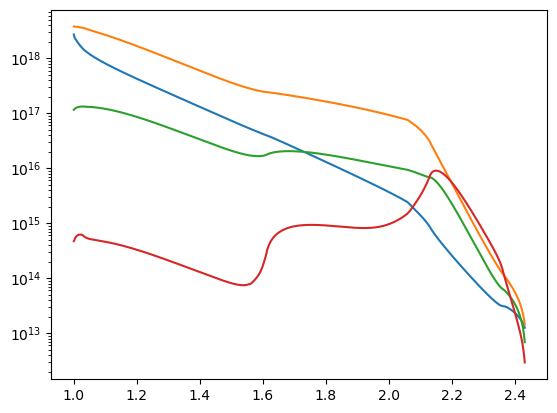

In [59]:
from breeding_blanket_setup import setup_bb_symmetric
from jax_sn.operators.transport_operator import TransportOperatorVmapPallas
solution_domain_1d, sources_1D, quadrature_set_1D = setup_bb_symmetric(1, degree, d_regions_base, n_elem_regions, 1.0, 10, tn_order, new_bb_data_dict)
sources_1D = jnp.broadcast_to(jnp.stack([sources_1D if i == 0 else jnp.zeros_like(sources_1D) for i in range(n_energy_groups)], axis=0)[:, None, ...], (n_energy_groups, quadrature_set_1D.n_angles, sources_1D.shape[0], solution_domain_1d.n_basis))
mgop_1d = jax_sn.operators.multi_group_operator.multi_group_operator_creation.create_multi_group_operator(solution_domain_1d, quadrature_set_1D, single_angle_transport_operator_cls=TransportOperatorVmapPallas)
solution_1d = _solve_multigroup_operator_rhs_scan(mgop_1d, sources_1D, mgsolver)

def interpolate_1d(r, solution_total, solution_domain):    
    flux_interp = [solution_domain.interpolate(r[:,None], solution_total.value[i,0]) for i in range(solution_total.value.shape[0])]
    return jnp.stack(flux_interp, axis=0)
    
n_flux_total = jnp.sum(fs_values_elem * solution_domain.solution_domain_data.precomputed_geometric_data.vol_jacobians_det / 2.0)

interpolated_flux_1d = interpolate_1d(jnp.linspace(1.232 + 1.2,  2.432 + 1.232, 1000), solution_1d, solution_domain_1d) / jnp.sqrt(4 * jnp.pi) * n_flux_total / 1.2 /10
overlap_matrix = jax_sn.energy_set.compute_overlap_matrix(groups_list, [14.3e6, 1e6, 300, 10, 0])
solution_collapsed_1d = jnp.einsum("ig, gj->ij", overlap_matrix, interpolated_flux_1d)
plt.semilogy(jnp.linspace(1.0, 2.432, 1000), solution_collapsed_1d.T, label="14.1 MeV")

(0.2, 1.432)

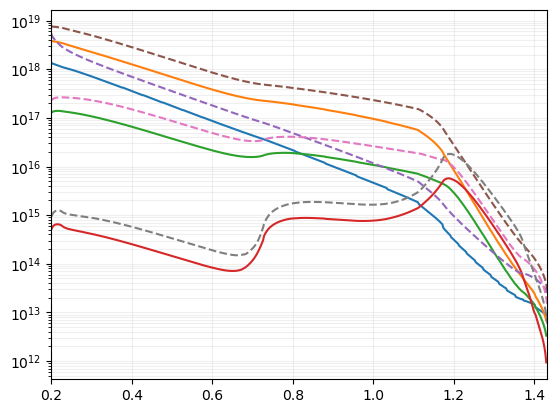

In [60]:
def line_interpolate(s_values, theta, phi, fs_base, solution_domain, solution_total):
    lines_rzp = fs_base.cylindrical_position(s_values, theta, phi)
    flux_interp = [solution_domain.interpolate(lines_rzp[:,0:2], solution_total.value[i,0]) for i in range(solution_total.value.shape[0])]
    return jnp.stack(flux_interp, axis=0)


slines = jnp.linspace(0, 2.432, 1000)
line_values = line_interpolate(slines,  - 0.5 * jnp.pi, phi, fs_base, solution_domain, solution_total) / jnp.sqrt(4 * jnp.pi)
overlap_matrix = jax_sn.energy_set.compute_overlap_matrix(groups_list, [14.3e6, 1e6, 300, 10, 0])
solution_collapsed = jnp.einsum("ig, gj->ij", overlap_matrix, line_values)
plt.semilogy(slines - 1.0, solution_collapsed.T, label='Eg 0')
plt.grid(which='both', alpha = 0.2)
plt.semilogy(jnp.linspace(0.2, 1.432, 1000), solution_collapsed_1d.T * 2, '--')
plt.xlim(0.2, 1.432)

In [61]:
s_max = 2.432

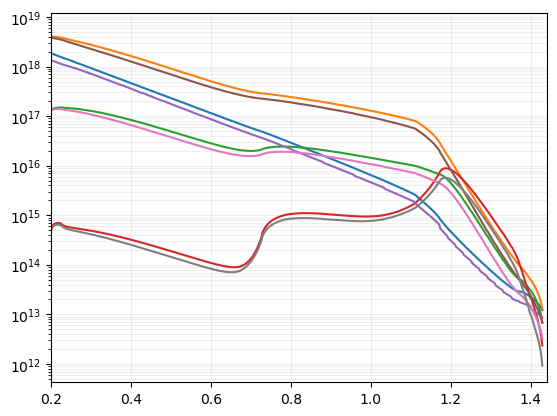

In [62]:
def plot_line(theta):
    slines = jnp.linspace(0, 2.432, 1000)
    line_values = line_interpolate(slines, theta, phi, fs_base, solution_domain, solution_total) / jnp.sqrt(4 * jnp.pi)
    overlap_matrix = jax_sn.energy_set.compute_overlap_matrix(groups_list, [14.3e6, 1e6, 300, 10, 0])
    solution_collapsed = jnp.einsum("ig, gj->ij", overlap_matrix, line_values)
    plt.semilogy(slines - 1.0, solution_collapsed.T, label='Eg 0')
    plt.grid(which='both', alpha = 0.2)
    plt.xlim(0.2, 1.442)

plot_line(0.5 * jnp.pi)
plot_line(- 0.5 * jnp.pi)

In [63]:
def extend_to_3d_mesh(mesh_pol):
    return jnp.stack([mesh_pol[0][:,0], jnp.zeros_like(mesh_pol[0][:,0]), mesh_pol[0][:,1]], axis=-1), mesh_pol[1]
plotter = pv.Plotter(shape =(1,2))
#plotter.add_mesh(mesh_to_pyvista_mesh(extend_to_3d_mesh(mesh_pol)), scalars = flux_interp, show_edges=False)
plotter.subplot(0,1)
plotter.add_mesh(mesh_to_pyvista_mesh(extend_to_3d_mesh(mesh_pol)), scalars = onp.log10(flux_interp), show_edges=False)
plotter.show()

Widget(value='<iframe src="http://localhost:37045/index.html?ui=P_0x732983a5d5e0_0&reconnect=auto" class="pyvi…

In [70]:
def extend_to_3d_mesh(mesh_pol):
    return jnp.stack([mesh_pol[0][:,0], jnp.zeros_like(mesh_pol[0][:,0]), mesh_pol[0][:,1]], axis=-1), mesh_pol[1]
plotter = pv.Plotter()
plotter.add_mesh(mesh_to_pyvista_mesh(extend_to_3d_mesh(mesh_pol)), scalars =flux_interp, show_edges=False, clim = (1e12, 30e12))
#plotter.add_mesh(mesh_to_pyvista_mesh(mesh_pol2), scalars = fs_values_elem, show_edges=True)
plotter.show()

Widget(value='<iframe src="http://localhost:37045/index.html?ui=P_0x73294cadddf0_7&reconnect=auto" class="pyvi…